# Lab 02 — Phát hiện biên Canny (bản tổng hợp)

Notebook này gộp 5 notebook thành phần (TV1–TV5) và sắp xếp lại **theo đúng 4 mục của đề bài**:

| Mục đề bài | Nội dung | Gốc từ |
|---|---|---|
| **1.** Thực hiện Canny bằng OpenCV và scikit-image | các bước trung gian, so sánh 2 thư viện | TV1 |
| **2.** Thay đổi tham số, quan sát, so sánh với giá trị mặc định | sigma, ngưỡng, aperture/L2, Auto-Canny | TV1, TV2 |
| **3.** Áp dụng cho các loại ảnh khác nhau, đánh giá, kết luận | nhiễu / tương phản thấp / nhiều chi tiết, 50 ảnh, IoU – P/R/F1 | TV2, TV3, TV4 |
| **4.** Kết hợp Canny với kỹ thuật khác | morphology + contour, Otsu, approxPolyDP, Hough | TV5 |

> Mọi nhận xét bên dưới được viết dựa trên số liệu in ra khi chạy notebook. Bộ dữ liệu không có *ground truth* biên, nên các chỉ số (số pixel biên, IoU giữa 2 thư viện) chỉ mô tả mức độ phát hiện và mức đồng thuận, **không** phải độ chính xác tuyệt đối.

## 0. Cài đặt chung

In [1]:
from pathlib import Path
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import canny
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 9, "font.family": "DejaVu Sans"})
pd.set_option("display.width", 160)


def find_lab2():
    # Chạy được từ repo root, lab_2/ hoặc lab_2/notebook/
    cwd = Path.cwd().resolve()
    for p in (cwd, *cwd.parents):
        for c in (p, p / "lab_2"):
            if (c / "data" / "input").is_dir():
                return c
    raise FileNotFoundError("Không tìm thấy lab_2/data/input - hãy mở notebook trong repo.")


LAB2 = find_lab2()
INPUT_DIR = LAB2 / "data" / "input"
FIG_DIR = LAB2 / "result" / "figures" / "final"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def read_img(name, gray=True):
    # np.fromfile + imdecode: an toàn với đường dẫn Unicode trên Windows
    data = np.fromfile(str(INPUT_DIR / name), np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(name)
    return img


def show(ax, img, title="", cmap="gray"):
    ax.imshow(img, cmap=cmap, **({"vmin": 0, "vmax": 255} if cmap == "gray" and img.dtype == np.uint8 else {}))
    ax.set_title(title)
    ax.axis("off")


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=130, bbox_inches="tight")


def pct(mask):
    return 100.0 * np.count_nonzero(mask) / mask.size


# ---- Hai hàm Canny dùng chung, đều trả về mask bool ----
def canny_cv(gray, low, high, sigma=1.0, aperture=3, l2=True):
    # OpenCV không tự làm mờ -> làm mờ Gaussian trước (kernel ~ 4 sigma mỗi phía)
    k = 2 * int(np.ceil(4 * sigma)) + 1
    blur = cv2.GaussianBlur(gray, (k, k), sigma)
    return cv2.Canny(blur, low, high, apertureSize=aperture, L2gradient=l2) > 0


def canny_sk(gray, sigma=1.0, low=0.1, high=0.2):
    # scikit-image tự làm mờ qua sigma; ngưỡng nằm trên thang [0, 1]
    return canny(gray / 255.0, sigma=sigma, low_threshold=low, high_threshold=high)


def bench(fn, n=30, warmup=3):
    # Trả về median (ms) của n lần chạy
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(n):
        s = time.perf_counter(); fn(); t.append((time.perf_counter() - s) * 1e3)
    return float(np.median(t))


def iou(a, b):
    u = np.count_nonzero(a | b)
    return np.count_nonzero(a & b) / u if u else 1.0   # hai mask rỗng: quy ước IoU = 1


print("LAB2 :", LAB2)
print("Ảnh  :", len(list(INPUT_DIR.glob("*.png"))), "file PNG")
print("OpenCV", cv2.__version__)

ModuleNotFoundError: No module named 'skimage'

---
## 1. Thực hiện thuật toán Canny bằng thư viện

Canny gồm 5 bước: **(1)** làm mờ Gaussian → **(2)** gradient Sobel (độ lớn, hướng) → **(3)** Non-Maximum Suppression làm mỏng biên → **(4)** ngưỡng kép (strong / weak) → **(5)** nối biên bằng hysteresis.

### 1.1 Các bước trung gian (OpenCV)

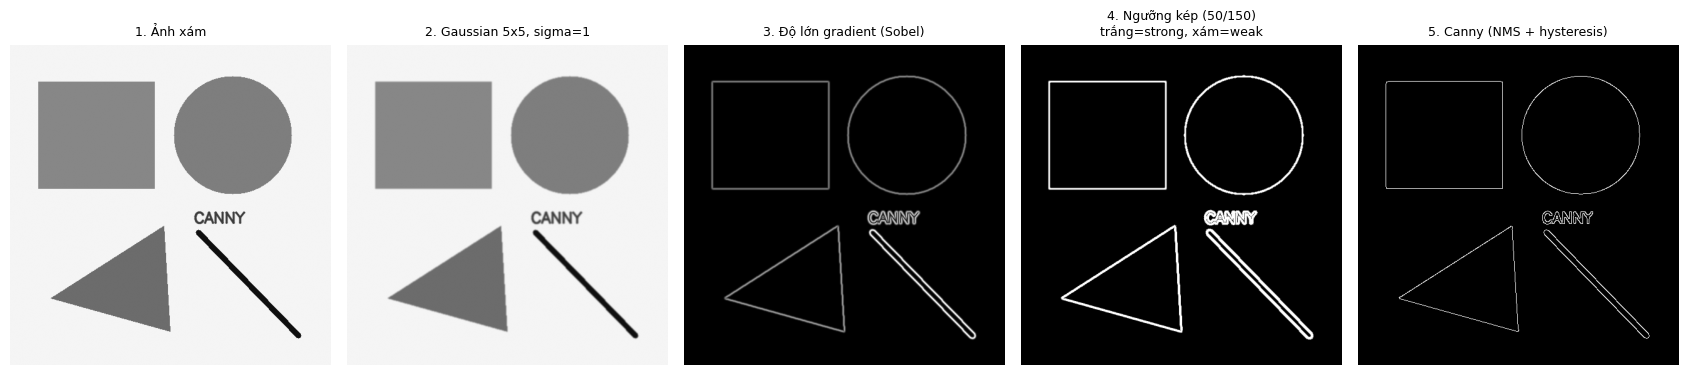

In [ ]:
IMG_GEOM, IMG_DETAIL = "01_hinh_hoc_ro_net.png", "04_anh_that_nhieu_chi_tiet.png"
LOW, HIGH = 50, 150

gray = read_img(IMG_GEOM)
blur = cv2.GaussianBlur(gray, (5, 5), 1.0)
gx = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)
mag = np.hypot(gx, gy)

# Ngưỡng kép: strong >= HIGH, weak trong [LOW, HIGH)
double_thr = np.zeros_like(gray)
double_thr[mag >= LOW] = 100     # weak
double_thr[mag >= HIGH] = 255    # strong
edges_cv = cv2.Canny(blur, LOW, HIGH, L2gradient=True)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
show(axes[0], gray, "1. Ảnh xám")
show(axes[1], blur, "2. Gaussian 5x5, sigma=1")
show(axes[2], (255 * mag / mag.max()).astype(np.uint8), "3. Độ lớn gradient (Sobel)")
show(axes[3], double_thr, f"4. Ngưỡng kép ({LOW}/{HIGH})\ntrắng=strong, xám=weak")
show(axes[4], edges_cv, "5. Canny (NMS + hysteresis)")
plt.tight_layout(); save_fig(fig, "s1_stages.png"); plt.show()

### 1.2 So sánh OpenCV và scikit-image trên cùng ảnh

Cấu hình tương đương: sigma = 1.0; OpenCV ngưỡng 50/150, `apertureSize=3`, `L2gradient=True`; scikit-image ngưỡng 50/255 và 150/255 (vì ảnh được chuẩn hóa về [0, 1]). Thời gian đo cả bước làm mờ + Canny cho cả hai (median của 30 lần chạy). Phép chia 255 chỉ đổi thang đo, **không** làm hai phép tính gradient trở nên giống hệt nhau.

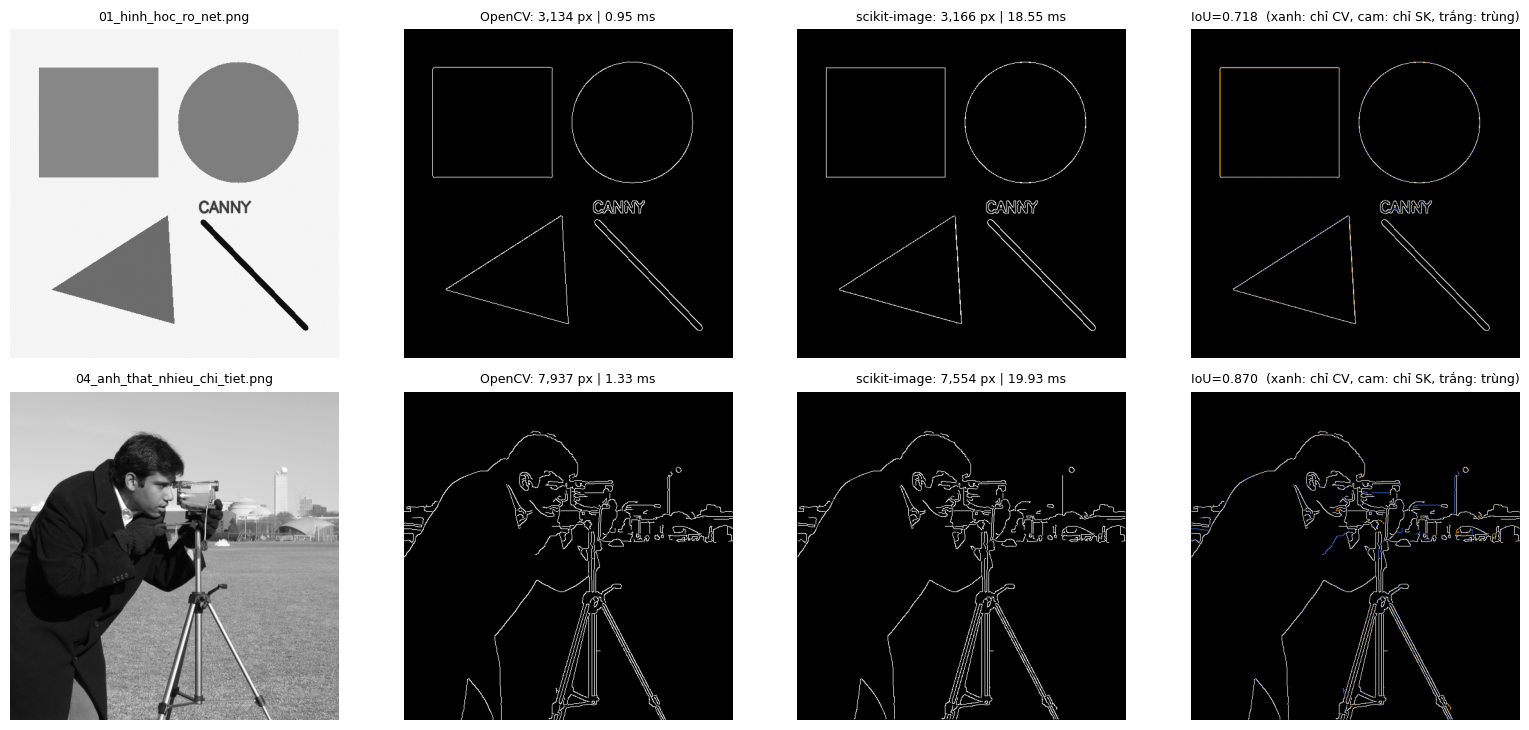

,ảnh,px biên OpenCV,px biên skimage,IoU,ms OpenCV,ms skimage,skimage/OpenCV (lần)
0,01_hinh_hoc_ro_net.png,3134,3166,0.718,0.95,18.55,19.5
1,04_anh_that_nhieu_chi_tiet.png,7937,7554,0.870,1.33,19.93,15.0


In [ ]:
rows, fig_rows = [], []
fig, axes = plt.subplots(2, 4, figsize=(16, 7.4))
for r, name in enumerate([IMG_GEOM, IMG_DETAIL]):
    g = read_img(name)
    a = canny_cv(g, LOW, HIGH)
    b = canny_sk(g, 1.0, LOW / 255, HIGH / 255)
    t_cv = bench(lambda: canny_cv(g, LOW, HIGH))
    t_sk = bench(lambda: canny_sk(g, 1.0, LOW / 255, HIGH / 255))

    ov = np.zeros((*g.shape, 3), np.uint8)
    ov[a & b] = (230, 230, 230); ov[a & ~b] = (60, 120, 255); ov[~a & b] = (255, 170, 30)

    show(axes[r, 0], g, name)
    show(axes[r, 1], a, f"OpenCV: {a.sum():,} px | {t_cv:.2f} ms")
    show(axes[r, 2], b, f"scikit-image: {b.sum():,} px | {t_sk:.2f} ms")
    axes[r, 3].imshow(ov); axes[r, 3].axis("off")
    axes[r, 3].set_title(f"IoU={iou(a, b):.3f}  (xanh: chỉ CV, cam: chỉ SK, trắng: trùng)")
    rows.append({"ảnh": name, "px biên OpenCV": int(a.sum()), "px biên skimage": int(b.sum()),
                 "IoU": round(iou(a, b), 3), "ms OpenCV": round(t_cv, 2), "ms skimage": round(t_sk, 2),
                 "skimage/OpenCV (lần)": round(t_sk / t_cv, 1)})
plt.tight_layout(); save_fig(fig, "s1_cv_vs_sk.png"); plt.show()
display(pd.DataFrame(rows))

**Nhận xét** *(số liệu lúc chạy thử; thời gian phụ thuộc máy):*
- Hai thư viện cho bản đồ biên **gần giống nhau** khi nhìn bằng mắt: 3.134 và 3.166 px trên ảnh hình học, 7.937 và 7.554 px trên ảnh thật.
- IoU chỉ là 0,718 (ảnh hình học) và 0,870 (ảnh thật). Biên Canny rộng 1 pixel nên khớp *đúng pixel* rất khắt khe: lệch nhẹ vài đoạn là IoU tụt rõ dù hình nhìn gần như trùng (xem thêm mục 3.3).
- OpenCV nhanh hơn khoảng **14–15 lần** (≈1–1,5 ms so với ≈20 ms) vì lõi C++.


| Tiêu chí | OpenCV `cv2.Canny` | scikit-image `skimage.feature.canny` |
|:--|:--|:--|
| Đầu vào | `uint8` [0, 255], ảnh xám | ảnh 2D, `float` [0, 1] hoặc `uint8` |
| Đầu ra | `uint8` (0 hoặc 255) | mảng `bool` |
| Làm mờ | tự làm trước (`GaussianBlur`) | tích hợp, qua tham số `sigma` |
| Ngưỡng | tuyệt đối trên thang gradient Sobel | theo thang [0, 1] (hoặc phân vị với `use_quantiles=True`) |
| Tham số riêng | `apertureSize` (3/5/7), `L2gradient` | `sigma`, `mode`, `mask`, `use_quantiles` |
| Giá trị mặc định | không có mặc định cho ngưỡng | `sigma=1.0`, ngưỡng tự suy theo kiểu dữ liệu (0.1 và 0.2 với ảnh float) |
| Tốc độ / dùng khi | nhanh (C++), hợp video/thời gian thực | chậm hơn (Python), hợp thí nghiệm, nghiên cứu |

---
## 2. Thay đổi tham số và quan sát kết quả

Dùng 3 ảnh: **hình học rõ nét** (01), **tương phản thấp** (02) và **ảnh thật nhiều chi tiết** (04). Phần này dùng scikit-image với ngưỡng trên thang [0, 1]; **cấu hình mặc định** là `sigma=1.0`, `low=0.1`, `high=0.2` (cũng là baseline của TV2).

In [ ]:
IMGS = {
    "Hình học (01)": read_img("01_hinh_hoc_ro_net.png"),
    "Tương phản thấp (02)": read_img("02_tuong_phan_thap.png"),
    "Nhiều chi tiết (04)": read_img("04_anh_that_nhieu_chi_tiet.png"),
}
BASE = dict(sigma=1.0, low=0.1, high=0.2)       # mặc định của scikit-image
records = []                                    # gom số liệu cho bảng tổng hợp


def run_grid(configs, title, fname):
    # configs: list[(nhãn, dict tham số)]; mỗi hàng = 1 ảnh, cột 0 = ảnh gốc
    fig, axes = plt.subplots(len(IMGS), len(configs) + 1, figsize=(3.4 * (len(configs) + 1), 3.1 * len(IMGS)),
                             squeeze=False)
    for r, (iname, g) in enumerate(IMGS.items()):
        show(axes[r, 0], g, iname)
        for c, (label, kw) in enumerate(configs, start=1):
            e = canny_sk(g, **kw)
            show(axes[r, c], e, f"{label}\n{e.sum():,} px ({pct(e):.2f}%)")
            records.append({"thí nghiệm": title, "ảnh": iname, "cấu hình": label,
                            "px biên": int(e.sum()), "% biên": round(pct(e), 3)})
    fig.suptitle(title, y=1.0, fontsize=12)
    plt.tight_layout(); save_fig(fig, fname); plt.show()

### 2.1 Thay đổi `sigma` (ngưỡng giữ mặc định 0.1 / 0.2)

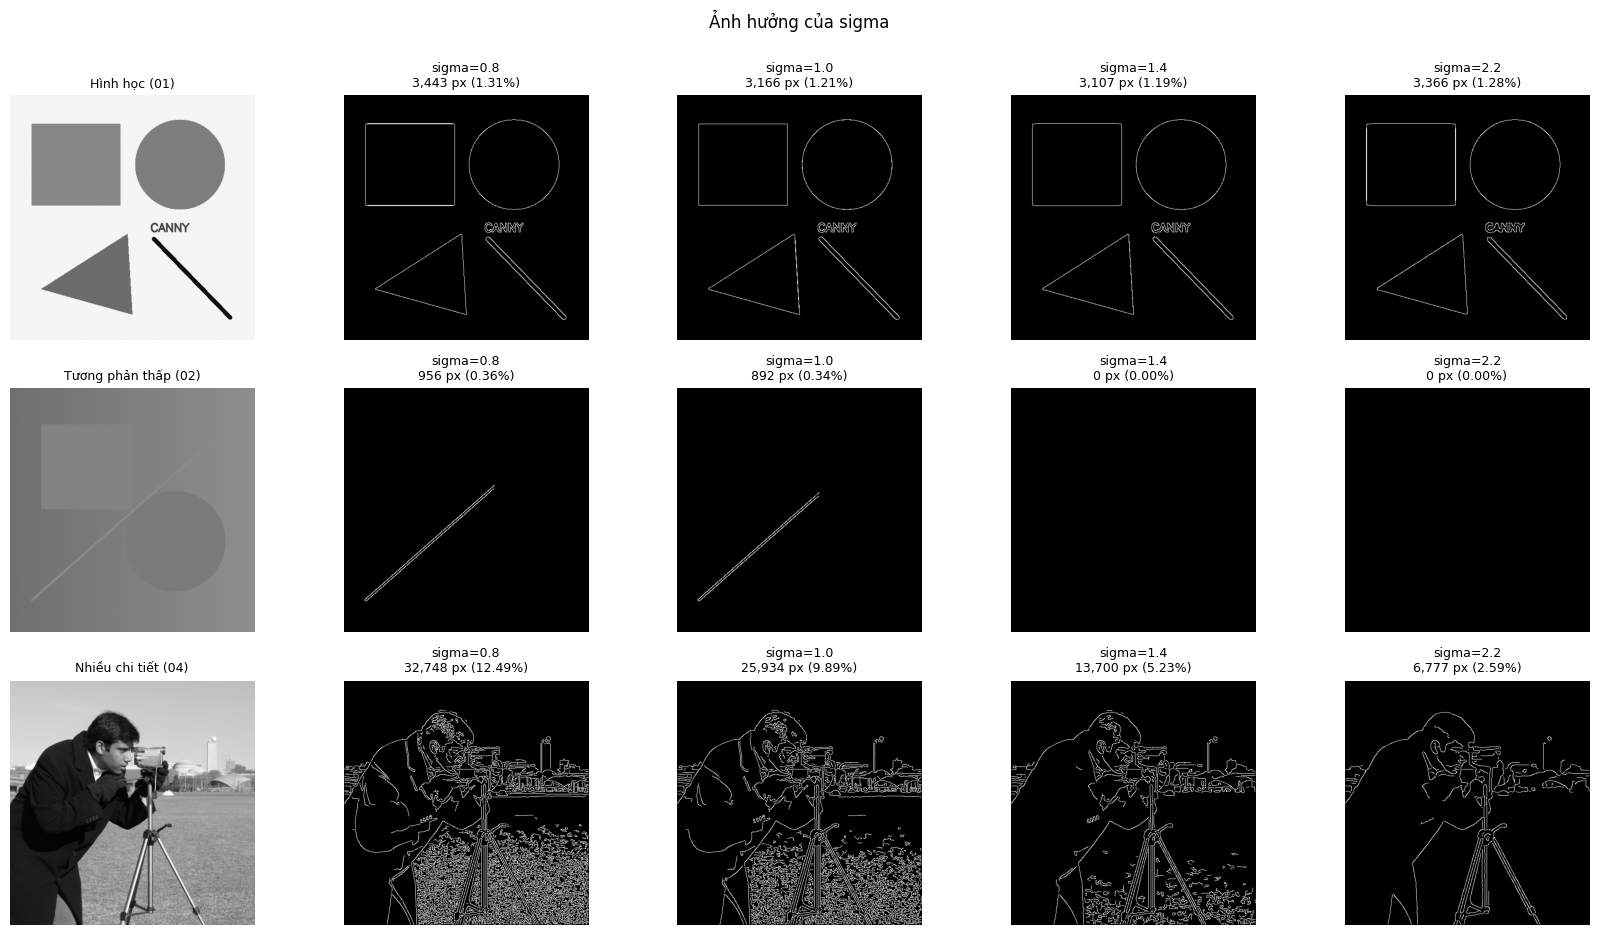

In [ ]:
run_grid([(f"sigma={s}", {**BASE, "sigma": s}) for s in (0.8, 1.0, 1.4, 2.2)],
         "Ảnh hưởng của sigma", "s2_sigma.png")

### 2.2 Thay đổi cặp ngưỡng (sigma = 1.0)

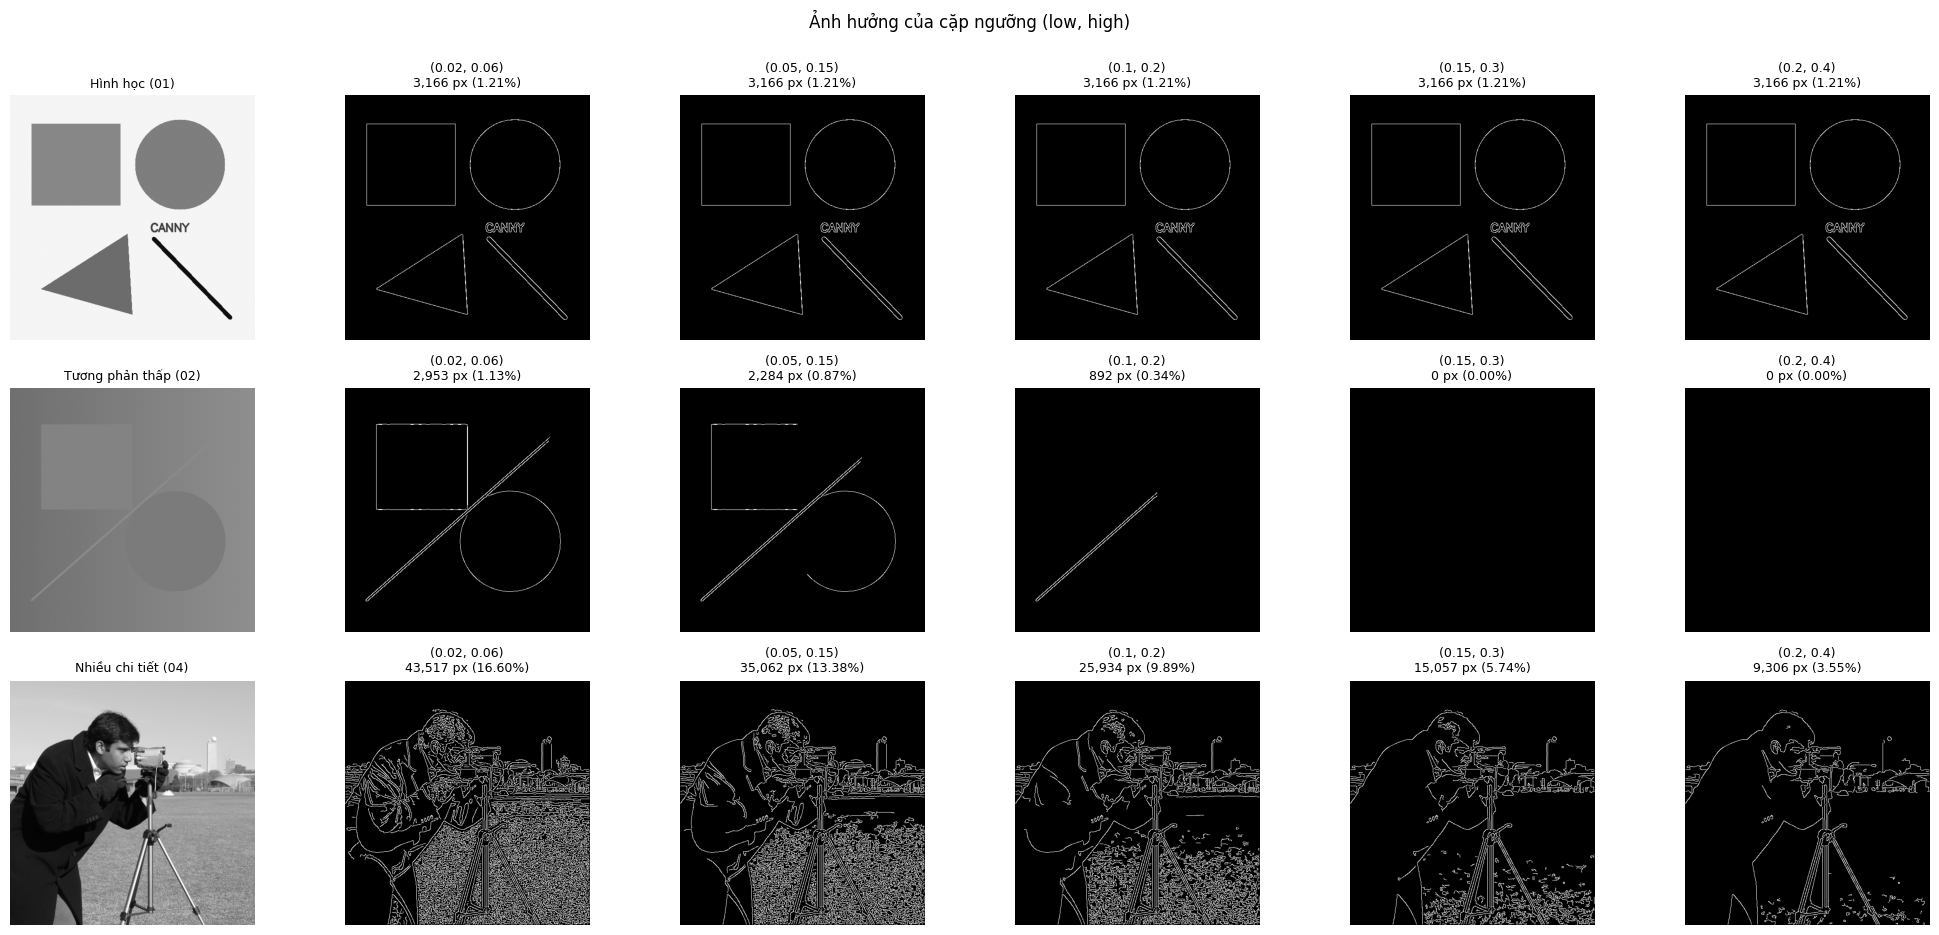

In [ ]:
run_grid([(f"({lo}, {hi})", {**BASE, "low": lo, "high": hi})
          for lo, hi in [(0.02, 0.06), (0.05, 0.15), (0.10, 0.20), (0.15, 0.30), (0.20, 0.40)]],
         "Ảnh hưởng của cặp ngưỡng (low, high)", "s2_threshold.png")

### 2.3 OpenCV: `apertureSize` và `L2gradient` (ảnh nhiều chi tiết, 50/150)

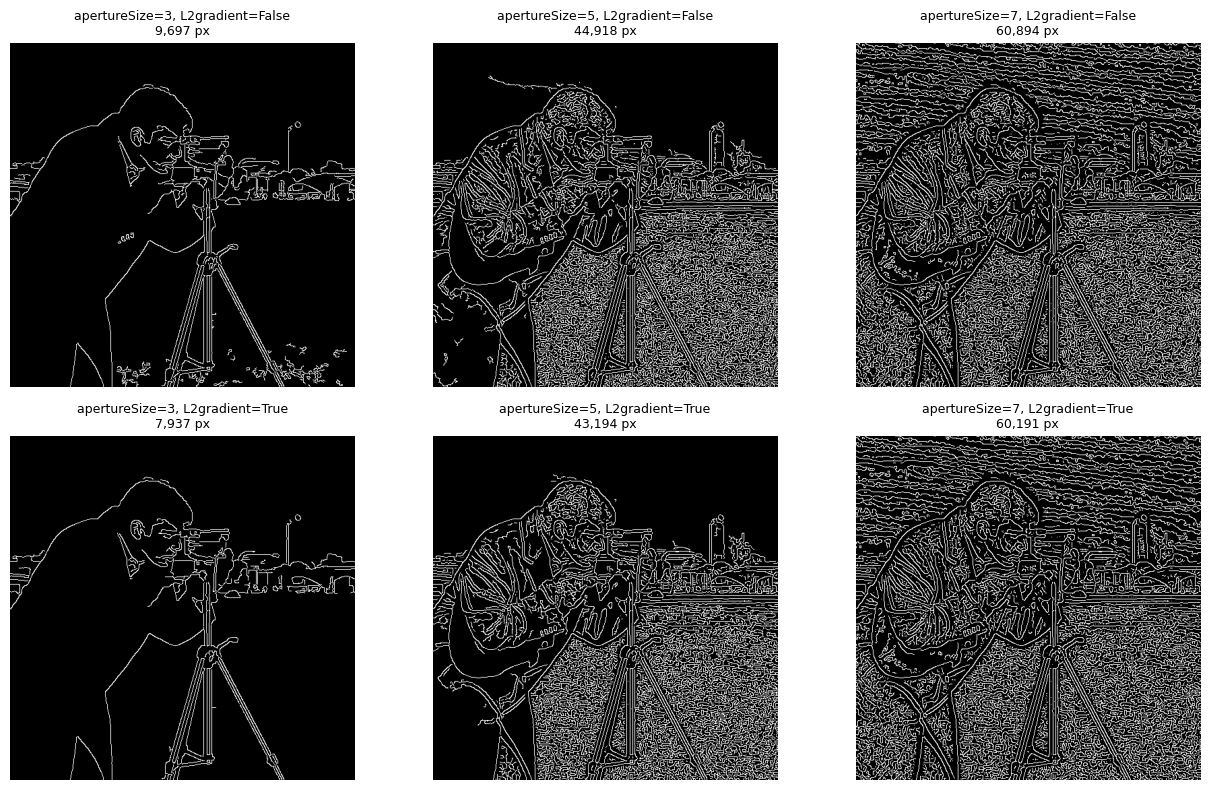

L2gradient,False,True
apertureSize,,
3,9697,7937
5,44918,43194
7,60894,60191


In [ ]:
g = IMGS["Nhiều chi tiết (04)"]
rows = []
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for c, ap in enumerate((3, 5, 7)):
    for r, l2 in enumerate((False, True)):
        e = canny_cv(g, 50, 150, sigma=1.0, aperture=ap, l2=l2)
        show(axes[r, c], e, f"apertureSize={ap}, L2gradient={l2}\n{e.sum():,} px")
        rows.append({"apertureSize": ap, "L2gradient": l2, "px biên": int(e.sum())})
plt.tight_layout(); save_fig(fig, "s2_aperture.png"); plt.show()
display(pd.DataFrame(rows).pivot(index="apertureSize", columns="L2gradient", values="px biên"))

### 2.4 So sánh với giá trị mặc định và Auto-Canny

Auto-Canny đặt ngưỡng theo trung vị cường độ ảnh: `lower = (1 - s) * median`, `upper = (1 + s) * median` với `s = 0.33`. Đây là cách *tự động* chọn ngưỡng, nhưng trung vị độ sáng không phản ánh độ mạnh của biên.

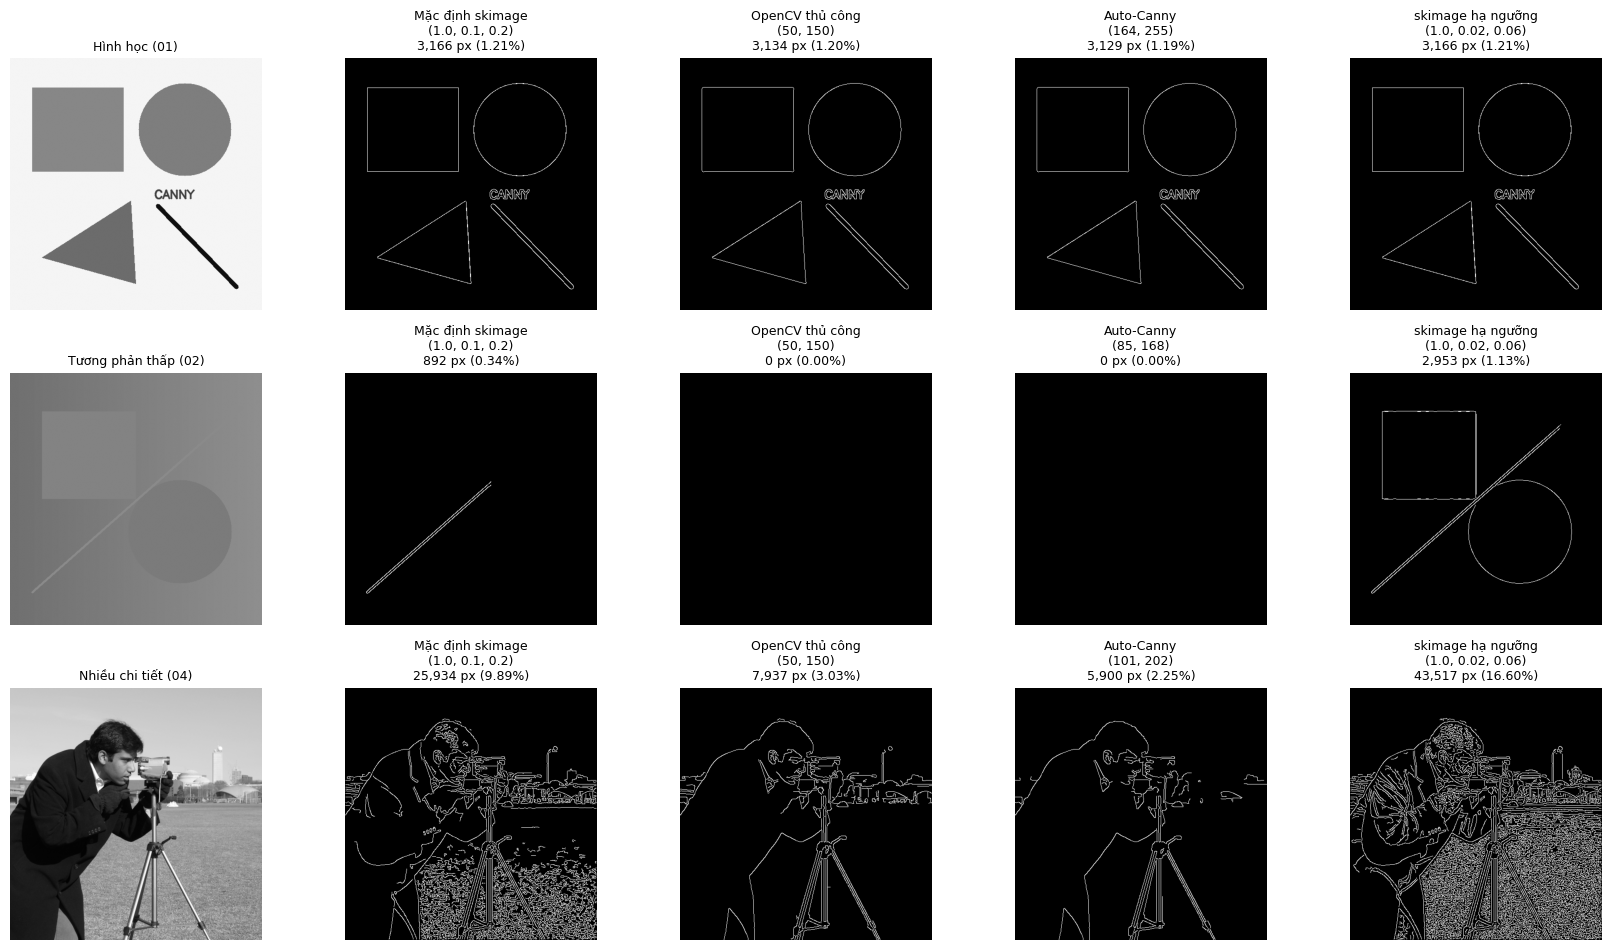

ảnh,Hình học (01),Nhiều chi tiết (04),Tương phản thấp (02)
phương pháp,,,
"Auto-Canny (101, 202)",NaN,2.251,NaN
"Auto-Canny (164, 255)",1.194,NaN,NaN
"Auto-Canny (85, 168)",NaN,NaN,0.000
"Mặc định skimage (1.0, 0.1, 0.2)",1.208,9.893,0.340
"OpenCV thủ công (50, 150)",1.196,3.028,0.000
"skimage hạ ngưỡng (1.0, 0.02, 0.06)",1.208,16.600,1.126


In [ ]:
def auto_canny(gray, s=0.33):
    m = float(np.median(gray))
    lo, hi = int(max(0, (1 - s) * m)), int(min(255, (1 + s) * m))
    return canny_cv(gray, lo, hi), lo, hi


fig, axes = plt.subplots(len(IMGS), 5, figsize=(17, 3.2 * len(IMGS)))
cmp_rows = []
for r, (iname, g) in enumerate(IMGS.items()):
    default = canny(g / 255.0)                       # đúng mặc định scikit-image
    manual = canny_cv(g, 50, 150)
    auto, lo, hi = auto_canny(g)
    tuned = canny_sk(g, sigma=1.0, low=0.02, high=0.06)   # hạ ngưỡng
    outs = [("Mặc định skimage\n(1.0, 0.1, 0.2)", default), ("OpenCV thủ công\n(50, 150)", manual),
            (f"Auto-Canny\n({lo}, {hi})", auto), ("skimage hạ ngưỡng\n(1.0, 0.02, 0.06)", tuned)]
    show(axes[r, 0], g, iname)
    for c, (lab, e) in enumerate(outs, start=1):
        show(axes[r, c], e, f"{lab}\n{e.sum():,} px ({pct(e):.2f}%)")
        cmp_rows.append({"ảnh": iname, "phương pháp": lab.replace("\n", " "), "px biên": int(e.sum()),
                         "% biên": round(pct(e), 3)})
plt.tight_layout(); save_fig(fig, "s2_default_vs_auto.png"); plt.show()
display(pd.DataFrame(cmp_rows).pivot(index="phương pháp", columns="ảnh", values="% biên"))

**Bảng tổng hợp** số pixel biên của mục 2.1–2.2:

In [ ]:
sumdf = pd.DataFrame(records)
for t in sumdf["thí nghiệm"].unique():
    print("\n" + t)
    display(sumdf[sumdf["thí nghiệm"] == t].pivot(index="cấu hình", columns="ảnh", values="px biên")
            [list(IMGS)])


Ảnh hưởng của sigma


ảnh,Hình học (01),Tương phản thấp (02),Nhiều chi tiết (04)
cấu hình,,,
sigma=0.8,3443,956,32748
sigma=1.0,3166,892,25934
sigma=1.4,3107,0,13700
sigma=2.2,3366,0,6777



Ảnh hưởng của cặp ngưỡng (low, high)


ảnh,Hình học (01),Tương phản thấp (02),Nhiều chi tiết (04)
cấu hình,,,
"(0.02, 0.06)",3166,2953,43517
"(0.05, 0.15)",3166,2284,35062
"(0.1, 0.2)",3166,892,25934
"(0.15, 0.3)",3166,0,15057
"(0.2, 0.4)",3166,0,9306


### Nhận xét mục 2
**Sigma** (ngưỡng mặc định 0,1/0,2):
- Ảnh hình học gần như không đổi (3.443 → 3.166 → 3.107 → 3.366 px): biên rất rõ nên bền với sigma.
- Ảnh nhiều chi tiết giảm đều khi tăng sigma: 32.748 → 25.934 → 13.700 → 6.777 px (sigma 0,8 → 2,2), tức làm mịn mạnh loại dần chi tiết nhỏ và texture cỏ.
- Ảnh tương phản thấp: sigma ≥ 1,4 cho **0 pixel biên** — làm mờ làm yếu thêm gradient vốn đã nhỏ.

**Ngưỡng** (sigma = 1):
- Ảnh hình học: 3.166 px ở **mọi** cặp ngưỡng (tương phản biên lớn hơn cả ngưỡng cao nhất thử).
- Ảnh tương phản thấp: 2.953 → 2.284 → 892 → 0 → 0 px khi tăng ngưỡng; từ (0,15; 0,30) trở lên mất hết biên.
- Ảnh nhiều chi tiết: 43.517 → 9.306 px; ngưỡng thấp kéo theo rất nhiều biên do texture cỏ, ngưỡng cao giữ ít chi tiết hơn.

**apertureSize / L2gradient** (OpenCV, 50/150, ảnh nhiều chi tiết):
- Cùng ngưỡng, chuẩn L1 cho nhiều biên hơn L2 (9.697 so với 7.937 px ở aperture 3) — hợp lý vì |Gx|+|Gy| ≥ √(Gx²+Gy²).
- Aperture 3 → 5 → 7 tăng mạnh số biên (7.937 → 43.194 → 60.191 px khi L2=True). Một lý do hợp lý là Sobel lớn hơn cho giá trị gradient lớn hơn nên cùng ngưỡng 50/150 trở nên “dễ vượt” hơn; kernel to cũng nhạy với kết cấu vùng rộng.

**So với mặc định và Auto-Canny:**
- Mặc định scikit-image (0,1/0,2 trên thang [0,1], tương đương khoảng 25/51 trên thang 0–255) *thấp hơn nhiều* ngưỡng OpenCV 50/150, nên hai cách cho kết quả rất khác trên ảnh nhiều chi tiết (9,89% so với 3,03% pixel biên). Không nên so “mặc định” với “thủ công” nếu chưa quy về cùng thang.
- Ảnh hình học: cả 4 cách đều ≈1,2% pixel biên — kết quả ổn định.
- Ảnh tương phản thấp: mặc định skimage chỉ tìm được đường chéo (892 px); OpenCV 50/150 và Auto-Canny (85/168) cho **0 pixel**; chỉ khi hạ ngưỡng xuống (0,02; 0,06) mới lộ cả hình vuông, hình tròn và đường chéo (2.953 px).
- Auto-Canny đặt ngưỡng theo trung vị *độ sáng*, không phản ánh độ mạnh của biên, nên không cải thiện được ảnh tương phản thấp và không tốt hơn rõ rệt ở hai ảnh còn lại.

---
## 3. Áp dụng Canny cho các loại ảnh khác nhau

### 3.1 Ba điều kiện: nhiều nhiễu – tương phản thấp – nhiều chi tiết

Giữ **một cặp ngưỡng cố định** (80/160, `L2gradient=True`) trước và sau tiền xử lý để so sánh công bằng:

| Điều kiện | Cách tạo ảnh | Tiền xử lý |
|---|---|---|
| Nhiều nhiễu | ảnh 04 + nhiễu Gaussian (σ=25, seed=42) | Gaussian 5×5, σ=1.2 |
| Tương phản thấp | ảnh 04, `convertScaleAbs(alpha=0.35, beta=100)` | CLAHE (clip 2.0, lưới 8×8) + Gaussian 3×3, σ=0.6 |
| Nhiều chi tiết | ảnh đồng xu 05 (không thêm nhiễu) | Gaussian nhẹ 3×3, σ=0.6 |

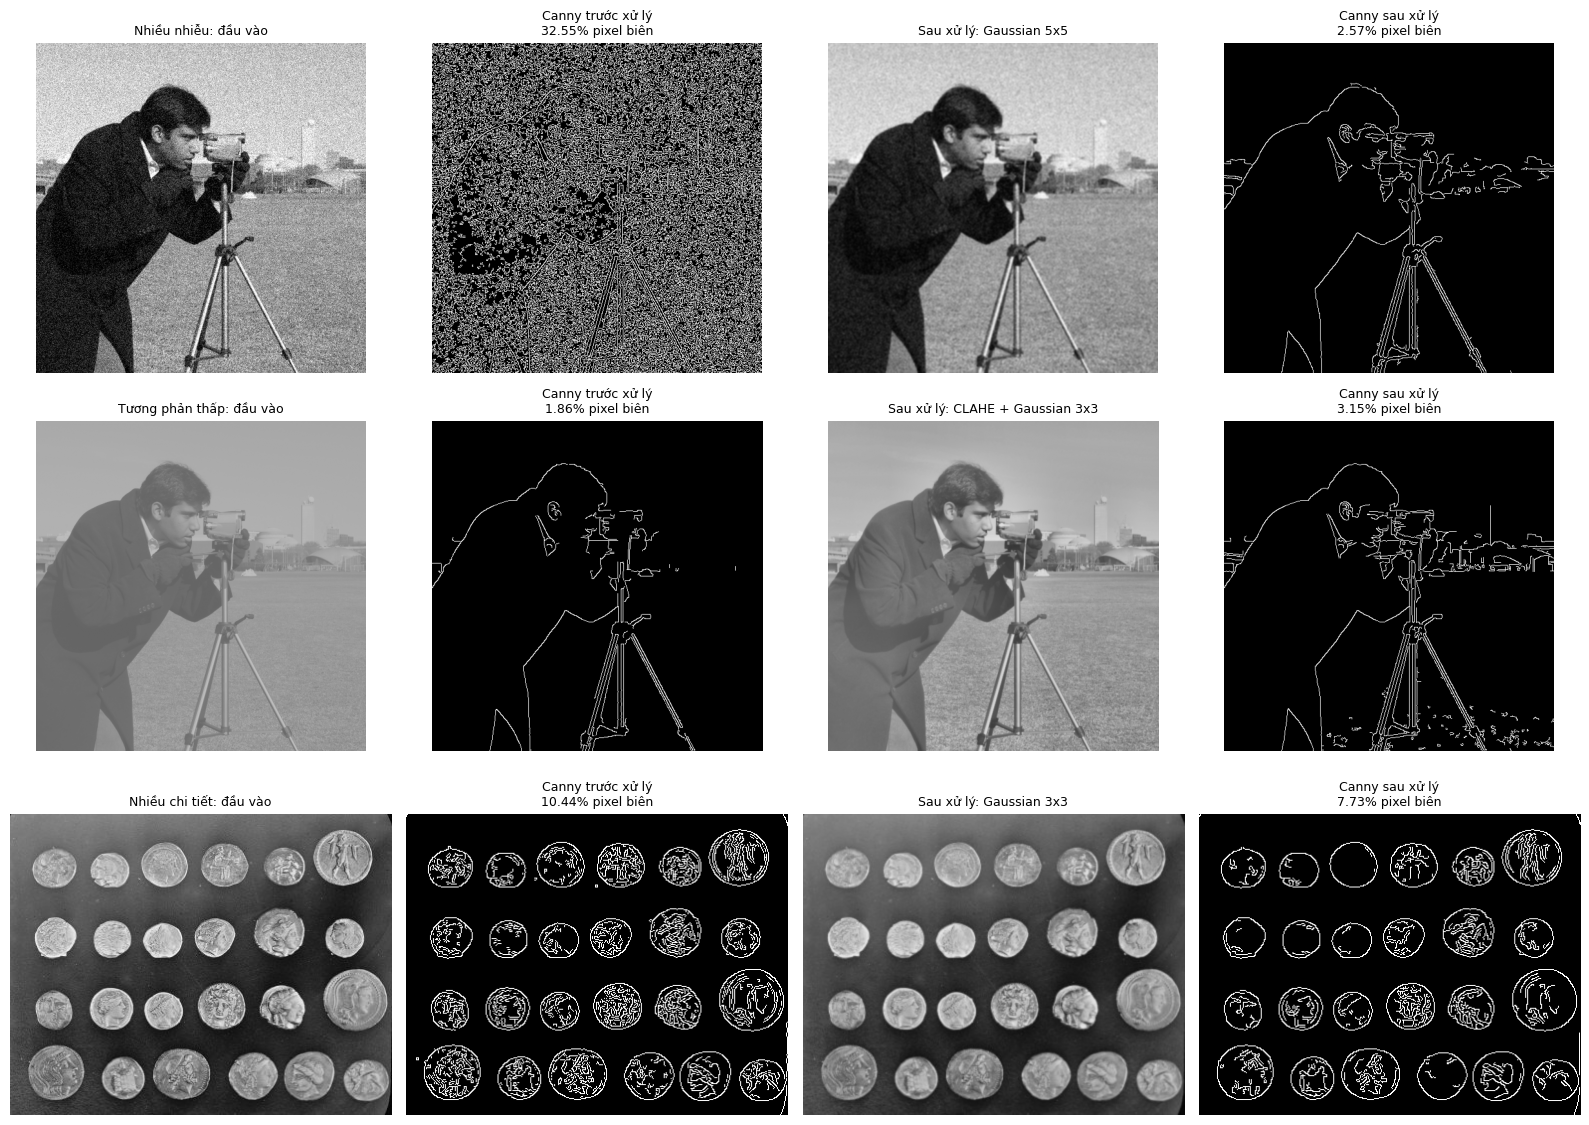

,điều kiện,% biên trước,% biên sau,tiền xử lý
0,Nhiều nhiễu,32.55,2.57,Gaussian 5x5
1,Tương phản thấp,1.86,3.15,CLAHE + Gaussian 3x3
2,Nhiều chi tiết,10.44,7.73,Gaussian 3x3


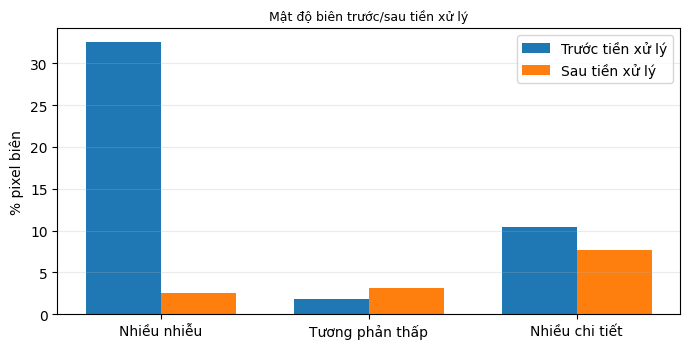

In [ ]:
camera = read_img("04_anh_that_nhieu_chi_tiet.png")
coins = read_img("05_dong_xu_phan_doan.png")
rng = np.random.default_rng(42)
noisy = np.clip(camera.astype(np.float32) + rng.normal(0, 25.0, camera.shape), 0, 255).astype(np.uint8)
low_contrast = cv2.convertScaleAbs(camera, alpha=0.35, beta=100)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

CASES = [
    ("Nhiều nhiễu", noisy, lambda x: cv2.GaussianBlur(x, (5, 5), 1.2), "Gaussian 5x5"),
    ("Tương phản thấp", low_contrast, lambda x: cv2.GaussianBlur(clahe.apply(x), (3, 3), 0.6), "CLAHE + Gaussian 3x3"),
    ("Nhiều chi tiết", coins, lambda x: cv2.GaussianBlur(x, (3, 3), 0.6), "Gaussian 3x3"),
]
c80 = lambda x: cv2.Canny(x, 80, 160, L2gradient=True) > 0

fig, axes = plt.subplots(3, 4, figsize=(16, 11.5))
rows = []
for r, (name, img, prep, prep_name) in enumerate(CASES):
    proc = prep(img)
    e0, e1 = c80(img), c80(proc)
    show(axes[r, 0], img, f"{name}: đầu vào")
    show(axes[r, 1], e0, f"Canny trước xử lý\n{pct(e0):.2f}% pixel biên")
    show(axes[r, 2], proc, f"Sau xử lý: {prep_name}")
    show(axes[r, 3], e1, f"Canny sau xử lý\n{pct(e1):.2f}% pixel biên")
    rows.append({"điều kiện": name, "% biên trước": round(pct(e0), 2), "% biên sau": round(pct(e1), 2),
                 "tiền xử lý": prep_name})
plt.tight_layout(); save_fig(fig, "s3_conditions.png"); plt.show()
cond_df = pd.DataFrame(rows); display(cond_df)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(cond_df)); w = 0.36
ax.bar(x - w / 2, cond_df["% biên trước"], w, label="Trước tiền xử lý")
ax.bar(x + w / 2, cond_df["% biên sau"], w, label="Sau tiền xử lý")
ax.set_xticks(x, cond_df["điều kiện"]); ax.set_ylabel("% pixel biên"); ax.legend(); ax.grid(axis="y", alpha=.25)
ax.set_title("Mật độ biên trước/sau tiền xử lý"); plt.tight_layout(); save_fig(fig, "s3_density.png"); plt.show()

**Nhận xét** (cùng cặp ngưỡng 80/160):
- **Nhiều nhiễu:** trước xử lý, nhiễu tạo ra bản đồ biên dày đặc các đoạn ngắn (**32,55%** pixel biên). Gaussian 5×5 đưa xuống **2,57%** và lộ lại đường bao người, máy ảnh, chân máy; đổi lại một số chi tiết nhỏ bị đứt hoặc mất.
- **Tương phản thấp:** mật độ biên tăng từ 1,86% lên **3,15%** sau CLAHE + blur nhẹ: biên yếu ở đường chân trời và tòa nhà hiện rõ hơn, nhưng cũng xuất hiện thêm vài đoạn biên nhỏ ở vùng cỏ — CLAHE khuếch đại cả kết cấu nền.
- **Nhiều chi tiết:** blur nhẹ giảm từ 10,44% xuống **7,73%**; đường bao đồng xu vẫn giữ, các nét nổi bên trong đồng xu ít đi. Nếu mục tiêu là giữ hoa văn thì không nên làm mờ mạnh.

### 3.2 Toàn bộ bộ 50 ảnh theo nhóm điều kiện

Cùng một cấu hình mặc định (scikit-image, σ=1.0, 0.1/0.2) cho tất cả ảnh. Lưu ý: 42 ảnh biến thể được *tổng hợp từ 8 ảnh gốc*, không phải 50 cảnh độc lập, nên ta so sánh theo nhóm điều kiện chứ không coi chúng là mẫu độc lập.

,số_ảnh,TB,min,max,ảnh_không_biên
nhóm,,,,,
Ảnh gốc,8,8.583,0.340,33.171,0
Tăng tương phản,6,6.110,1.100,11.424,0
Giảm tương phản,6,3.263,0.000,6.601,1
Nhiễu Gaussian,6,18.099,1.240,31.214,0
Nhiễu muối tiêu,6,18.427,6.307,28.059,0
Làm mờ Gaussian,6,2.787,1.089,6.874,0
Sáng không đều,6,3.426,0.282,8.737,0
Gradient/texture,6,12.885,1.110,29.749,0


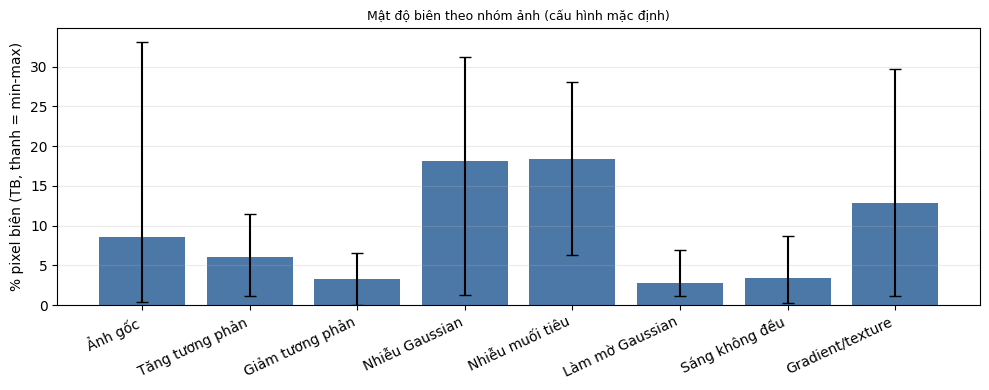

In [ ]:
GROUPS = [(1, 8, "Ảnh gốc"), (9, 14, "Tăng tương phản"), (15, 20, "Giảm tương phản"),
          (21, 26, "Nhiễu Gaussian"), (27, 32, "Nhiễu muối tiêu"), (33, 38, "Làm mờ Gaussian"),
          (39, 44, "Sáng không đều"), (45, 50, "Gradient/texture")]


def group_of(name):
    k = int(name[:2])
    return next(lab for lo, hi, lab in GROUPS if lo <= k <= hi)


rows = []
for p in sorted(INPUT_DIR.glob("*.png")):
    g = read_img(p.name)
    e = canny_sk(g)
    rows.append({"file": p.name, "nhóm": group_of(p.name), "% biên": pct(e), "px biên": int(e.sum()),
                 "độ sáng TB": g.mean(), "độ lệch chuẩn": g.std()})
df50 = pd.DataFrame(rows)
order = [lab for _, _, lab in GROUPS]
summ = (df50.groupby("nhóm")
        .agg(số_ảnh=("file", "count"), TB=("% biên", "mean"), min=("% biên", "min"), max=("% biên", "max"),
             ảnh_không_biên=("px biên", lambda s: int((s == 0).sum())))
        .loc[order].round(3))
display(summ)

fig, ax = plt.subplots(figsize=(10, 4))
m = summ["TB"].values
ax.bar(order, m, yerr=[m - summ["min"].values, summ["max"].values - m], capsize=4, color="#4C78A8")
ax.set_ylabel("% pixel biên (TB, thanh = min-max)"); ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=25, ha="right"); ax.set_title("Mật độ biên theo nhóm ảnh (cấu hình mặc định)")
plt.tight_layout(); save_fig(fig, "s3_groups.png"); plt.show()

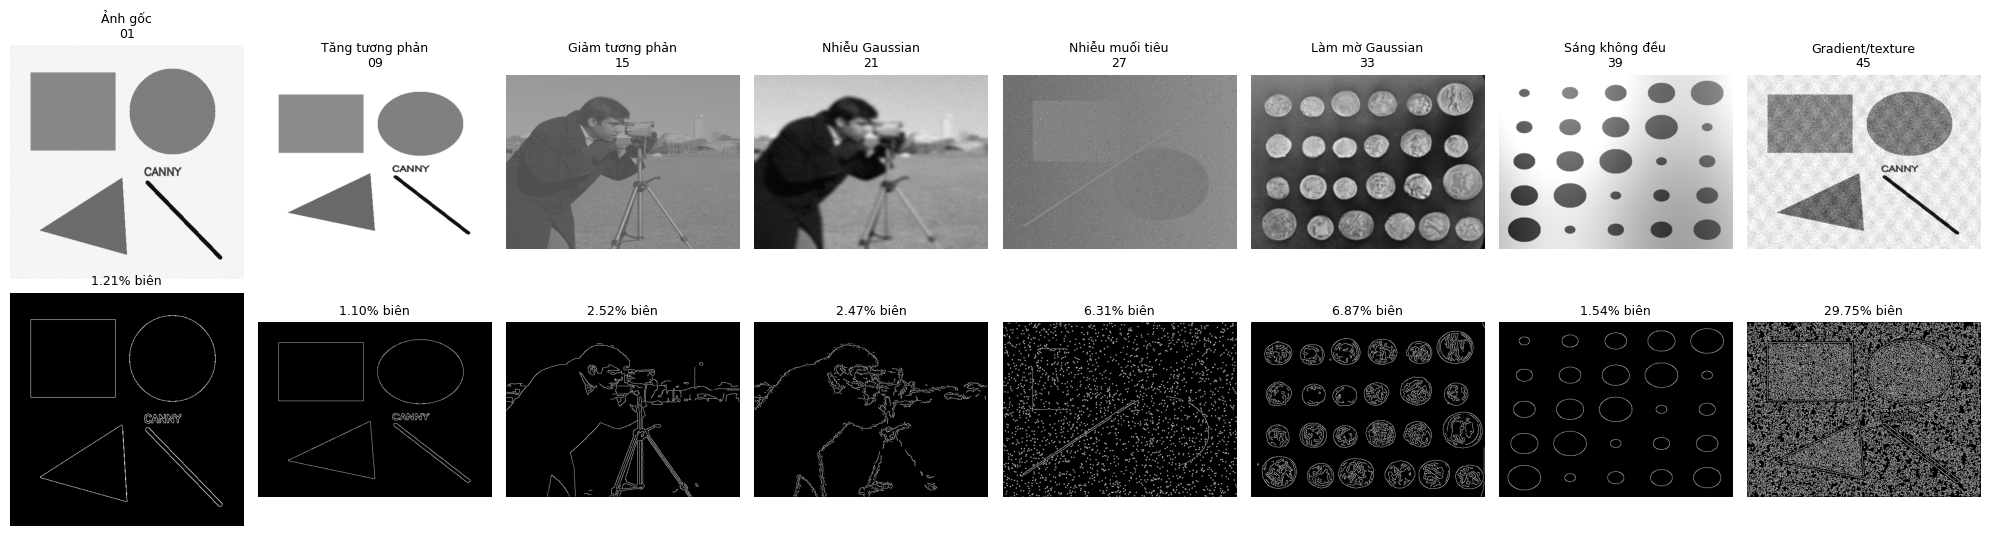

In [ ]:
# Ví dụ trực quan: 1 ảnh đại diện mỗi nhóm
reps = df50.groupby("nhóm").head(1).set_index("nhóm").loc[order]["file"].tolist()
fig, axes = plt.subplots(2, 8, figsize=(20, 5.4))
for i, (lab, f) in enumerate(zip(order, reps)):
    g = read_img(f)
    show(axes[0, i], g, f"{lab}\n{f[:2]}")
    show(axes[1, i], canny_sk(g), f"{pct(canny_sk(g)):.2f}% biên")
plt.tight_layout(); save_fig(fig, "s3_group_examples.png"); plt.show()

**Nhận xét** (cùng cấu hình mặc định cho cả bộ):
- Nhóm **nhiễu Gaussian** (TB 18,1%) và **nhiễu muối tiêu** (TB 18,4%) có mật độ biên cao nhất; phần lớn là biên giả do nhiễu chứ không phải cấu trúc thật. Nhóm **gradient/texture** cũng cao (TB 12,9%, tối đa 29,7%).
- Nhóm **làm mờ** thấp nhất (TB 2,8%): chi tiết nhỏ bị xóa nên Canny chỉ còn bắt các biên lớn.
- Nhóm **giảm tương phản** (TB 3,3%) có 1 ảnh **0% pixel biên**; nhóm **sáng không đều** dao động rộng (0,28% – 8,74%).
- Cùng một cấu hình cho tỷ lệ biên khác nhau rất xa giữa các nhóm. Vì vậy % pixel biên chỉ mô tả *lượng* biên, không nói lên *chất lượng* biên (ảnh nhiễu có % cao nhưng chất lượng thấp).

### 3.3 Đánh giá kết quả: IoU, Precision / Recall / F1

Không có bản đồ biên chuẩn nên ta làm 2 việc:
1. **Kiểm chứng các công thức** (IoU, TP/FP/FN, P/R/F1) bằng một ví dụ có nhãn nhỏ tính tay được.
2. Dùng **IoU giữa OpenCV và scikit-image** như thước đo *mức đồng thuận* (không phải độ chính xác).

$$IoU=\frac{|A\cap B|}{|A\cup B|},\quad P=\frac{TP}{TP+FP},\quad R=\frac{TP}{TP+FN},\quad F1=\frac{2TP}{2TP+FP+FN}$$

In [ ]:
def edge_metrics(pred, gt):
    p, g = pred != 0, gt != 0
    tp, fp, fn = (p & g).sum(), (p & ~g).sum(), (~p & g).sum()
    div = lambda a, b: a / b if b else float("nan")
    return {"TP": int(tp), "FP": int(fp), "FN": int(fn), "Precision": div(tp, tp + fp),
            "Recall": div(tp, tp + fn), "F1": div(2 * tp, 2 * tp + fp + fn), "IoU": iou(p, g)}


# Ví dụ tính tay: 5 pixel tham chiếu, 4 pixel dự đoán -> TP=3, FP=1, FN=2
gt = np.zeros((8, 8), bool); gt[2, 2:5] = True; gt[3:5, 4] = True
pr = np.zeros_like(gt); pr[2, 2:4] = True; pr[3, 4] = True; pr[5, 5] = True
m = edge_metrics(pr, gt)
assert (m["TP"], m["FP"], m["FN"]) == (3, 1, 2)
assert np.isclose(m["Precision"], 0.75) and np.isclose(m["Recall"], 0.6)
assert np.isclose(m["F1"], 2 / 3) and np.isclose(m["IoU"], 0.5)
display(pd.DataFrame([m]).round(3))

# Hạn chế của khớp đúng pixel: 2 đường giống hệt nhau nhưng lệch 1 pixel -> IoU = 0
a = np.zeros((8, 8), bool); b = a.copy(); a[1:7, 3] = True; b[1:7, 4] = True
print("IoU của 2 đường thẳng lệch 1 pixel:", iou(a, b))

,TP,FP,FN,Precision,Recall,F1,IoU
0,3,1,2,0.75,0.6,0.667,0.5


IoU của 2 đường thẳng lệch 1 pixel: 0.0


,ảnh,cấu hình,px OpenCV,px skimage,IoU,cả hai rỗng,ms OpenCV,ms skimage
0,Hình học (01),Cơ sở (50/150),3134,3166,0.718,False,0.96,18.92
1,Hình học (01),Ngưỡng thấp (20/60),3137,3166,0.717,False,0.99,20.10
2,Hình học (01),Ngưỡng cao (100/200),3132,3165,0.718,False,1.01,19.82
3,Tương phản thấp (02),Cơ sở (50/150),0,0,1.000,True,0.88,18.19
4,Tương phản thấp (02),Ngưỡng thấp (20/60),1044,1011,0.963,False,0.94,17.99
5,Tương phản thấp (02),Ngưỡng cao (100/200),0,0,1.000,True,0.87,17.11
6,Nhiều chi tiết (04),Cơ sở (50/150),7937,7554,0.870,False,1.33,20.91
7,Nhiều chi tiết (04),Ngưỡng thấp (20/60),26591,25811,0.793,False,2.26,21.25
8,Nhiều chi tiết (04),Ngưỡng cao (100/200),6025,5837,0.896,False,1.14,18.48


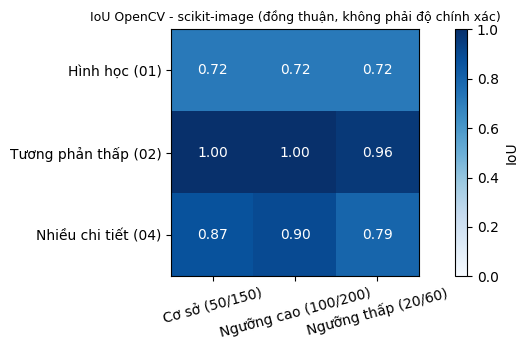

In [ ]:
CONFIGS = [("Cơ sở", 50, 150), ("Ngưỡng thấp", 20, 60), ("Ngưỡng cao", 100, 200)]
rows = []
for iname, g in IMGS.items():
    for cname, lo, hi in CONFIGS:
        a = canny_cv(g, lo, hi)
        b = canny_sk(g, 1.0, lo / 255, hi / 255)
        rows.append({"ảnh": iname, "cấu hình": f"{cname} ({lo}/{hi})", "px OpenCV": int(a.sum()),
                     "px skimage": int(b.sum()), "IoU": round(iou(a, b), 3),
                     "cả hai rỗng": (a.sum() == 0 and b.sum() == 0),
                     "ms OpenCV": round(bench(lambda: canny_cv(g, lo, hi), n=10), 2),
                     "ms skimage": round(bench(lambda: canny_sk(g, 1.0, lo / 255, hi / 255), n=10), 2)})
iou_df = pd.DataFrame(rows)
display(iou_df)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
mat = iou_df.pivot(index="ảnh", columns="cấu hình", values="IoU").loc[list(IMGS)]
im = ax.imshow(mat.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(mat.shape[1]), mat.columns, rotation=15); ax.set_yticks(range(mat.shape[0]), mat.index)
for i, j in np.ndindex(mat.shape):
    ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center",
            color="white" if mat.values[i, j] > .6 else "black")
fig.colorbar(im, label="IoU"); ax.set_title("IoU OpenCV - scikit-image (đồng thuận, không phải độ chính xác)")
plt.tight_layout(); save_fig(fig, "s3_iou_heatmap.png"); plt.show()

### Nhận xét và kết luận mục 3
**Về chỉ số:** công thức IoU/Precision/Recall/F1 đã được kiểm chứng bằng ví dụ tính tay (TP=3, FP=1, FN=2 → P=0,75; R=0,60; F1=0,667; IoU=0,50). Hai đường thẳng giống hệt nhưng lệch 1 pixel có **IoU = 0**: khớp đúng pixel rất khắt khe, muốn đánh giá thực sự cần ground truth và quy tắc cho phép dung sai vị trí.

**Về đồng thuận OpenCV – scikit-image** (9 cặp 3 ảnh × 3 cấu hình):
- Ảnh hình học: IoU ≈ 0,72 ở cả ba cấu hình (số pixel biên gần như không đổi theo ngưỡng).
- Ảnh nhiều chi tiết: IoU 0,87 (50/150), **0,79** (20/60), 0,90 (100/200) — ngưỡng thấp giữ nhiều biên yếu/texture, đó là nơi hai thư viện khác nhau nhiều nhất.
- Ảnh tương phản thấp: ở 50/150 và 100/200 **cả hai mask đều rỗng** nên IoU = 1 theo quy ước, *không* phải bằng chứng phát hiện tốt; ở 20/60 hai bên cùng tìm được ≈1.000 px và IoU = 0,96.
- OpenCV nhanh hơn scikit-image ở cả 9 trường hợp (≈1–3 ms so với ≈17–22 ms).

**Kết luận rút ra từ mục 3:**
1. Chọn tiền xử lý theo *nguyên nhân* làm hỏng ảnh: Gaussian cho nhiễu, CLAHE hoặc hạ ngưỡng cho tương phản thấp, làm mờ nhẹ và ngưỡng cao hơn cho ảnh nhiều chi tiết; luôn kiểm tra lại biên giả sau khi tiền xử lý.
2. Không có một cặp (sigma, ngưỡng) tốt cho mọi ảnh; số pixel biên không phải thước đo chất lượng.
3. Muốn kết luận về độ chính xác phải có ground truth; khi không có, chỉ nên nói về mức đồng thuận và quan sát trực quan.

---
## 4. Kết hợp Canny với các kỹ thuật khác

### 4.1 Phân đoạn vùng: Canny → morphology → contour → mask

Quy trình: ảnh xám → Gaussian 5×5 (σ=1) → Canny (50/150) → *closing* (ellipse 3×3, 2 lần) → dilate → `findContours` (chỉ contour ngoài) → loại contour quá nhỏ (diện tích < max(30, 0.02% ảnh)) → mask.

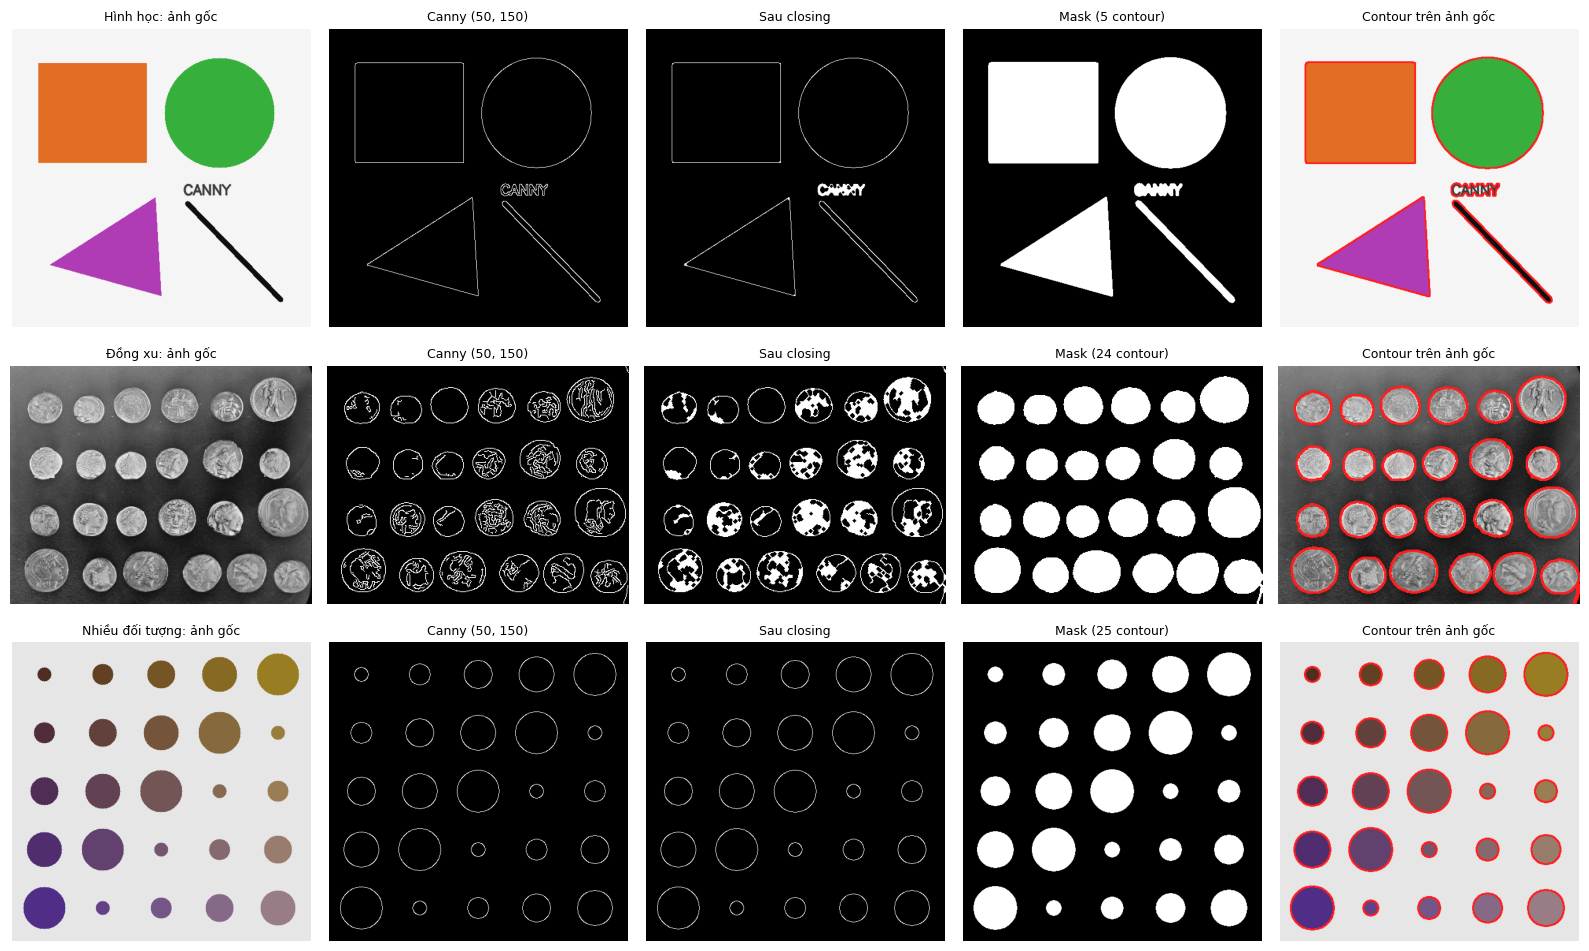

Closing kernel 3x3: 25 contour
Closing kernel 7x7: 25 contour


In [ ]:
SAMPLES = {"Hình học": "01_hinh_hoc_ro_net.png", "Đồng xu": "05_dong_xu_phan_doan.png",
           "Nhiều đối tượng": "08_nhieu_doi_tuong.png"}
K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))


def segment(bgr, close_k=K3):
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(cv2.GaussianBlur(g, (5, 5), 1.0), 50, 150)
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, close_k, iterations=2)
    dil = cv2.dilate(closed, K3)
    cnts, _ = cv2.findContours(dil, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    min_area = max(30, 0.0002 * g.size)
    kept = [c for c in cnts if cv2.contourArea(c) >= min_area]
    mask = np.zeros_like(g); cv2.drawContours(mask, kept, -1, 255, cv2.FILLED)
    ov = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).copy(); cv2.drawContours(ov, kept, -1, (255, 30, 30), 2)
    return dict(gray=g, edges=edges, closed=closed, contours=kept, mask=mask, overlay=ov,
                rgb=cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))


seg = {k: segment(read_img(f, gray=False)) for k, f in SAMPLES.items()}
fig, axes = plt.subplots(3, 5, figsize=(16, 9.6))
for r, (k, s) in enumerate(seg.items()):
    axes[r, 0].imshow(s["rgb"]); axes[r, 0].set_title(f"{k}: ảnh gốc"); axes[r, 0].axis("off")
    show(axes[r, 1], s["edges"], "Canny (50, 150)")
    show(axes[r, 2], s["closed"], "Sau closing")
    show(axes[r, 3], s["mask"], f"Mask ({len(s['contours'])} contour)")
    axes[r, 4].imshow(s["overlay"]); axes[r, 4].set_title("Contour trên ảnh gốc"); axes[r, 4].axis("off")
plt.tight_layout(); save_fig(fig, "s4_segmentation.png"); plt.show()

# Ảnh hưởng của kích thước kernel closing (ảnh nhiều đối tượng)
bgr8 = read_img(SAMPLES["Nhiều đối tượng"], gray=False)
for k in (3, 7):
    s = segment(bgr8, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    print(f"Closing kernel {k}x{k}: {len(s['contours'])} contour")

### 4.2 So sánh với phân đoạn ngưỡng Otsu (ảnh đồng xu)

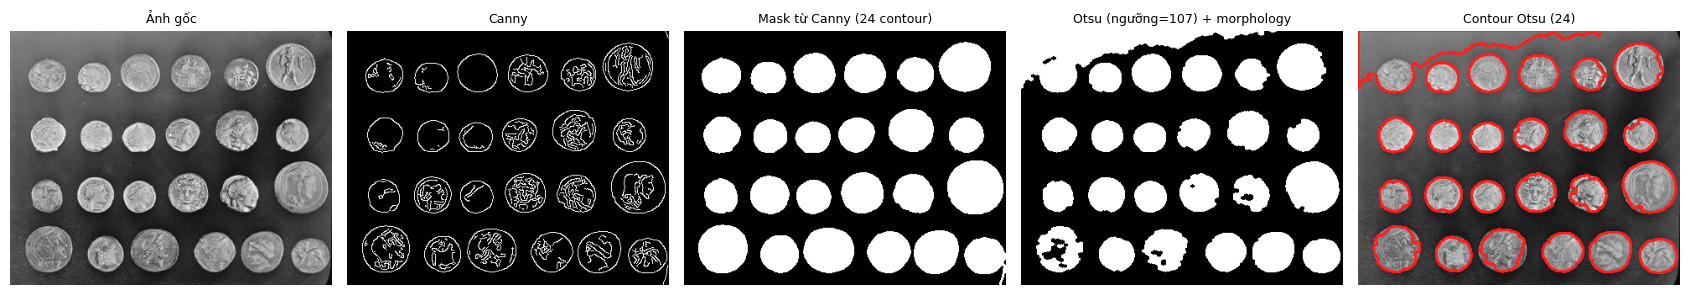

Số contour từ Canny: 24 | từ Otsu: 24


In [ ]:
s = seg["Đồng xu"]
g = s["gray"]
thr, otsu = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
if np.mean(otsu == 255) > 0.5:
    otsu = cv2.bitwise_not(otsu)                    # đối tượng là vùng trắng
K5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
otsu = cv2.morphologyEx(cv2.morphologyEx(otsu, cv2.MORPH_OPEN, K5), cv2.MORPH_CLOSE, K5)
oc, _ = cv2.findContours(otsu, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
oc = [c for c in oc if cv2.contourArea(c) > 100]
ov = s["rgb"].copy(); cv2.drawContours(ov, oc, -1, (255, 30, 30), 2)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
axes[0].imshow(s["rgb"]); axes[0].set_title("Ảnh gốc"); axes[0].axis("off")
show(axes[1], s["edges"], "Canny")
show(axes[2], s["mask"], f"Mask từ Canny ({len(s['contours'])} contour)")
show(axes[3], otsu, f"Otsu (ngưỡng={thr:.0f}) + morphology")
axes[4].imshow(ov); axes[4].set_title(f"Contour Otsu ({len(oc)})"); axes[4].axis("off")
plt.tight_layout(); save_fig(fig, "s4_canny_vs_otsu.png"); plt.show()
print("Số contour từ Canny:", len(s["contours"]), "| từ Otsu:", len(oc))

### 4.3 Nhận dạng hình dạng: `approxPolyDP`, circularity và Hough Circle

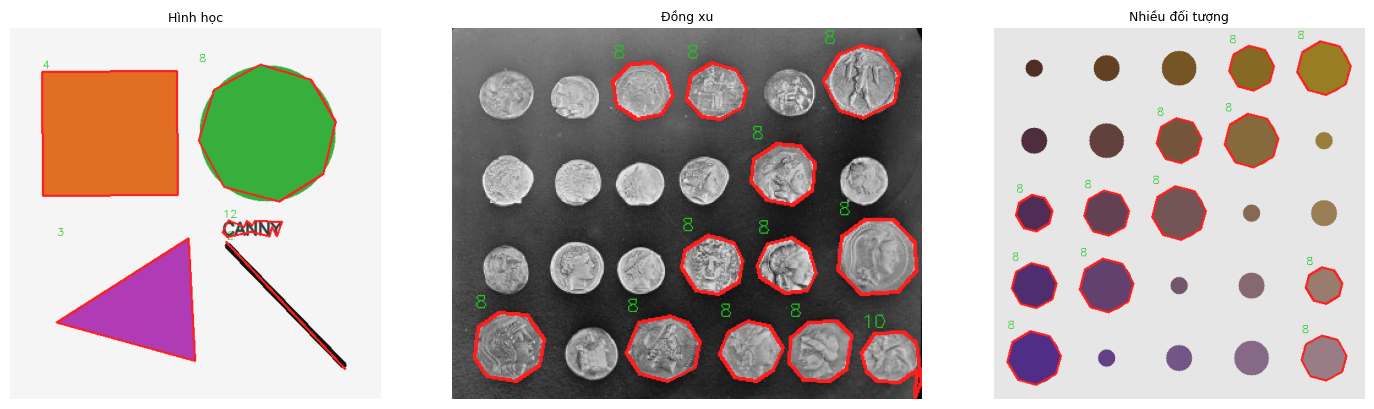

,ảnh,diện tích,chu vi,số đỉnh,hình ước lượng,circularity
0,Hình học,32507,717,4,Tứ giác,0.794
1,Hình học,28316,629,8,Đa giác/nhiều cạnh,0.900
2,Hình học,16478,619,3,Tam giác,0.540
3,Hình học,2639,497,2,Chưa xác định,0.134
4,Hình học,1338,278,12,Đa giác/nhiều cạnh,0.218
5,Đồng xu,3354,216,8,Đa giác/nhiều cạnh,0.900
6,Đồng xu,2792,199,8,Đa giác/nhiều cạnh,0.884
7,Đồng xu,2642,193,8,Đa giác/nhiều cạnh,0.893
8,Đồng xu,2529,191,8,Đa giác/nhiều cạnh,0.876
9,Đồng xu,2170,175,8,Đa giác/nhiều cạnh,0.895


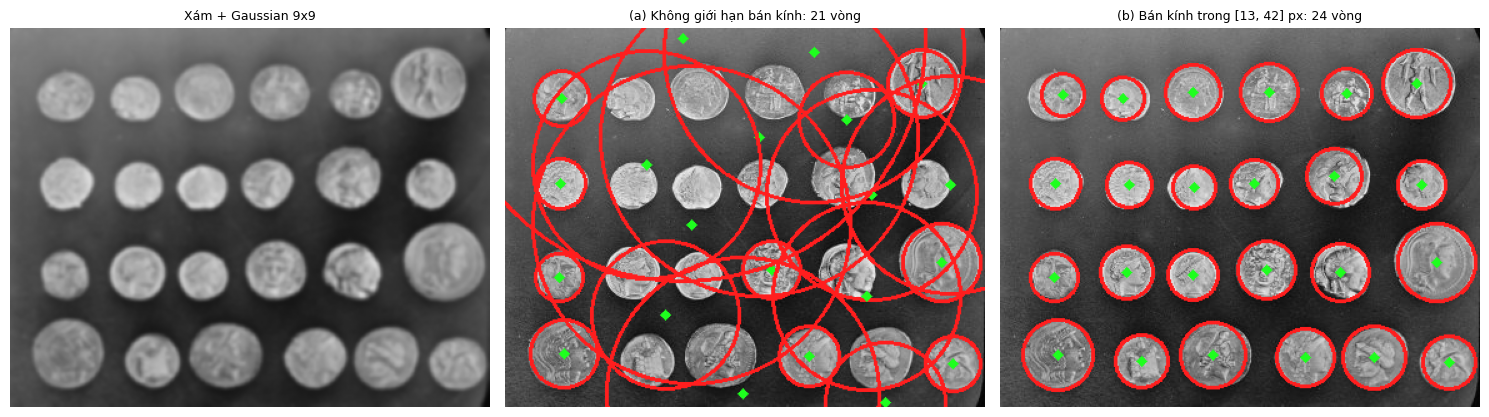

Circularity các contour đồng xu: TB = 0.869 | min = 0.503 | max = 0.901
Số vòng tròn Hough: (a) không giới hạn = 21 | (b) có giới hạn bán kính = 24


In [ ]:
def shape_name(v):
    return {3: "Tam giác", 4: "Tứ giác", 5: "Ngũ giác", 6: "Lục giác"}.get(v, "Đa giác/nhiều cạnh" if v > 6 else "Chưa xác định")


rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (k, s) in zip(axes, seg.items()):
    canvas = s["rgb"].copy()
    for cnt in sorted(s["contours"], key=cv2.contourArea, reverse=True)[:12]:
        area, per = cv2.contourArea(cnt), cv2.arcLength(cnt, True)
        if per <= 0 or area < 80:
            continue
        approx = cv2.approxPolyDP(cnt, 0.02 * per, True)
        x, y, _, _ = cv2.boundingRect(approx)
        cv2.drawContours(canvas, [approx], -1, (255, 30, 30), 2)
        cv2.putText(canvas, str(len(approx)), (x, max(12, y - 4)), cv2.FONT_HERSHEY_SIMPLEX, .5, (30, 200, 30), 1)
        rows.append({"ảnh": k, "diện tích": round(area), "chu vi": round(per), "số đỉnh": len(approx),
                     "hình ước lượng": shape_name(len(approx)),
                     "circularity": round(4 * np.pi * area / per ** 2, 3)})
    ax.imshow(canvas); ax.set_title(k); ax.axis("off")
plt.tight_layout(); save_fig(fig, "s4_approxpoly.png"); plt.show()
shape_df = pd.DataFrame(rows)
display(shape_df.groupby("ảnh").head(6).reset_index(drop=True))

# Hough Circle trên ảnh đồng xu (không phụ thuộc vào contour)
blur9 = cv2.GaussianBlur(coins, (9, 9), 1.5)
radii = np.sqrt(np.array([cv2.contourArea(c) for c in seg["Đồng xu"]["contours"]]) / np.pi)
r_min, r_med, r_max = int(0.7 * radii.min()), float(np.median(radii)), int(1.3 * radii.max())


def hough_draw(circles):
    canvas = seg["Đồng xu"]["rgb"].copy(); n = 0
    if circles is not None:
        for x, y, rad in np.round(circles[0]).astype(int):
            cv2.circle(canvas, (x, y), rad, (255, 30, 30), 2); cv2.circle(canvas, (x, y), 2, (30, 255, 30), 3); n += 1
    return canvas, n


# (a) Không giới hạn bán kính (cấu hình gốc của TV5)
c_free = cv2.HoughCircles(blur9, cv2.HOUGH_GRADIENT, dp=1.2, minDist=max(20, coins.shape[0] // 5),
                          param1=100, param2=32, minRadius=10, maxRadius=0)
# (b) Giới hạn bán kính theo kích thước đồng xu suy ra từ contour Canny
c_bound = cv2.HoughCircles(blur9, cv2.HOUGH_GRADIENT, dp=1.2, minDist=int(1.2 * r_med),
                           param1=100, param2=30, minRadius=r_min, maxRadius=r_max)
img_a, n_a = hough_draw(c_free); img_b, n_b = hough_draw(c_bound)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
show(axes[0], blur9, "Xám + Gaussian 9x9")
axes[1].imshow(img_a); axes[1].set_title(f"(a) Không giới hạn bán kính: {n_a} vòng"); axes[1].axis("off")
axes[2].imshow(img_b); axes[2].set_title(f"(b) Bán kính trong [{r_min}, {r_max}] px: {n_b} vòng"); axes[2].axis("off")
plt.tight_layout(); save_fig(fig, "s4_hough.png"); plt.show()
circ = [4 * np.pi * cv2.contourArea(c) / cv2.arcLength(c, True) ** 2 for c in seg["Đồng xu"]["contours"]
        if cv2.contourArea(c) > 50 and cv2.arcLength(c, True) > 0]
print("Circularity các contour đồng xu: TB =", round(float(np.mean(circ)), 3),
      "| min =", round(float(np.min(circ)), 3), "| max =", round(float(np.max(circ)), 3))
print("Số vòng tròn Hough: (a) không giới hạn =", n_a, "| (b) có giới hạn bán kính =", n_b)

### Nhận xét mục 4
- **Phân đoạn từ biên:** ảnh hình học cho 5 contour (hình vuông, tròn, tam giác, đường chéo và chữ “CANNY” bị gộp thành một khối). Ảnh đồng xu cho **24 contour = 24 đồng xu**, ảnh nhiều đối tượng cho **25 contour = 25 vật thể**. Closing lấp các khe hở trên biên đồng xu nên mask thành vùng đặc.
- **Kích thước kernel closing:** 3×3 và 7×7 cùng cho 25 contour trên ảnh nhiều đối tượng, vì các vật thể ở đây cách xa nhau; nguy cơ “nhập vùng” khi kernel lớn chỉ xuất hiện khi vật thể sát nhau (không thể hiện ở ảnh này).
- **Canny so với Otsu** (đồng xu): cả hai đều đếm được 24 contour nhưng **số lượng bằng nhau không có nghĩa chất lượng bằng nhau**. Mặt nạ Otsu có một vùng nền ở góc trên trái bị nhập với đồng xu (nền sáng dần) và vài đồng xu bị thủng; mặt nạ từ Canny gọn hơn, nhưng cần closing và phụ thuộc vào biên có khép kín hay không.
- **approxPolyDP:** vuông → 4 đỉnh, tam giác → 3 đỉnh, đường chéo → 2 đỉnh. Hình tròn bị xấp xỉ thành **8 đỉnh** (ε = 2% chu vi) nên chỉ dựa vào số đỉnh sẽ gọi nhầm là “đa giác”; cần thêm **circularity** (đồng xu TB ≈ 0,87, cao nhất 0,90; hình tròn lý tưởng = 1).
- **Hough Circle:** nếu không giới hạn bán kính (cấu hình gốc của TV5) ra 21 vòng, trong đó nhiều vòng rất lớn là **sai**. Giới hạn bán kính theo kích thước đồng xu suy ra từ contour (13–42 px) cho **24 vòng khớp 24 đồng xu**. Hough không cần biên khép kín nhưng cần tri thức về kích thước đối tượng.

---
## 5. Kết luận chung
| Tình huống | Hướng xử lý đã kiểm chứng trong notebook |
|:--|:--|
| Biên rõ, tương phản cao (ảnh hình học) | Hầu hết cấu hình đều ổn, kết quả bền với sigma và ngưỡng |
| Ảnh nhiễu | Gaussian blur trước Canny; tăng sigma từ từ để không mất chi tiết nhỏ |
| Tương phản thấp | CLAHE hoặc hạ ngưỡng; ngưỡng mặc định/Auto-Canny có thể cho 0 biên |
| Nhiều texture/chi tiết | Tăng sigma hoặc ngưỡng để giảm biên rối; chấp nhận mất chi tiết mảnh |
| Cần vùng/đối tượng | Canny → closing → contour → mask, kiểm tra biên có khép kín không |
| Cần nhận dạng hình | approxPolyDP + circularity, hoặc Hough có giới hạn bán kính |

1. **Thư viện:** OpenCV và scikit-image cho kết quả tương tự (IoU 0,72–0,96 ở các cặp có biên); OpenCV nhanh hơn khoảng 10–15 lần. scikit-image tiện cho thí nghiệm vì tích hợp sigma và ngưỡng chuẩn hóa [0, 1], nhưng ngưỡng mặc định của nó **không** tương đương ngưỡng OpenCV thường dùng.
2. **Tham số:** sigma và ngưỡng quyết định *lượng* biên: tăng sigma hoặc ngưỡng làm giảm biên (và mất chi tiết yếu); hạ ngưỡng giữ biên yếu nhưng kéo theo texture/nhiễu. Aperture lớn và chuẩn L1 cũng làm tăng số biên ở cùng ngưỡng.
3. **Loại ảnh:** cùng một cấu hình cho kết quả rất khác nhau giữa nhiễu, tương phản thấp, mờ, nhiều texture. Cần tiền xử lý theo nguyên nhân và điều chỉnh tham số theo ảnh; Auto-Canny dựa trung vị độ sáng không đảm bảo tốt hơn.
4. **Đánh giá:** số pixel biên và IoU giữa hai thư viện chỉ cho biết mức độ phát hiện và mức đồng thuận. Đánh giá độ chính xác cần ground truth và quy tắc dung sai vị trí; hai mask rỗng cho IoU = 1 không có ý nghĩa.
5. **Kết hợp kỹ thuật:** Canny + morphology + contour cho vùng/đối tượng tốt khi biên khép kín; Hough và approxPolyDP/circularity bổ trợ cho nhận dạng hình, nhưng đều là *ước lượng* cần chỉnh tham số theo dữ liệu.